# 7장 4차시 실습 : sales_clean.csv 로 모델을 고른다
`data_analysis` 폴더에서. 2차시 `ml.ipynb` 와 같은 글꼴 셀로 시작합니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform
from sklearn.model_selection import train_test_split, cross_val_score

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

## ① 읽고 나눈다 : 총액을 수량과 단가로

In [2]:
sales = pd.read_csv("sales_clean.csv")
X = sales[["quantity", "unit_price"]]
y = sales["total_sales"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
print("training :", len(X_train), " test :", len(X_test))

training : 803  test : 201


## ② 선형 회귀와 결정 트리

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

lin = LinearRegression().fit(X_train, y_train)
tree = DecisionTreeRegressor(random_state=0).fit(X_train, y_train)
print("linear regression  test R² :", round(lin.score(X_test, y_test), 3))
print("decision tree      test R² :", round(tree.score(X_test, y_test), 3))

linear regression  test R² : 0.862
decision tree      test R² : 0.994


## ③ 특징 하나를 더한다 : 수량 × 단가

In [4]:
X2_train = X_train.assign(qp=X_train["quantity"] * X_train["unit_price"])
X2_test  = X_test.assign(qp=X_test["quantity"] * X_test["unit_price"])
lin2 = LinearRegression().fit(X2_train, y_train)
print("linear + qp        test R² :", round(lin2.score(X2_test, y_test), 3))
print("coef :", lin2.coef_.round(3), " intercept :", round(lin2.intercept_, 1))

linear + qp        test R² : 1.0
coef : [0. 0. 1.]  intercept : -0.0


## ④ max_depth 를 바꾸면 : training 과 test

In [5]:
rows = []
for dep in [1, 2, 3, 5, 8, 12, None]:
    m = DecisionTreeRegressor(max_depth=dep, random_state=0).fit(X_train, y_train)
    rows.append([str(dep), m.get_n_leaves(),
                 round(m.score(X_train, y_train), 3), round(m.score(X_test, y_test), 3)])
pd.DataFrame(rows, columns=["max_depth", "leaves", "training R²", "test R²"])

,max_depth,leaves,training R²,test R²
0,1,2,0.361,0.346
1,2,4,0.739,0.711
2,3,8,0.876,0.846
3,5,32,0.972,0.961
4,8,250,0.998,0.991
5,12,781,1.000,0.994
6,None,800,1.000,0.994


## ⑤ 교차검증 : 나눔 한 번을 믿지 않는다

In [6]:
for dep in [3, 5, 8, 12, None]:
    s = cross_val_score(DecisionTreeRegressor(max_depth=dep, random_state=0), X, y, cv=5)
    print(f"max_depth {str(dep):4s}  mean {s.mean():.3f}  std {s.std():.3f}")

max_depth 3     mean 0.845  std 0.019
max_depth 5     mean 0.961  std 0.003
max_depth 8     mean 0.992  std 0.000
max_depth 12    mean 0.995  std 0.000
max_depth None  mean 0.995  std 0.001


## ⑥ time series : CO2 다음 달 예측

In [7]:
co2 = pd.read_csv("co2_monthly.csv")
yc = co2["co2"]
Xc = pd.DataFrame({f"lag{k}": yc.shift(k) for k in range(1, 13)}).dropna()   # 지난 12 달
yc = yc.loc[Xc.index]
n = 60                                     # 마지막 60 달이 test. 섞지 않음
Xc_train, Xc_test, yc_train, yc_test = Xc[:-n], Xc[-n:], yc[:-n], yc[-n:]
print("training :", len(Xc_train), " test :", len(Xc_test))

training : 454  test : 60


In [8]:
from sklearn.metrics import mean_absolute_error

lin_ts = LinearRegression().fit(Xc_train, yc_train)
tree_ts = DecisionTreeRegressor(random_state=0).fit(Xc_train, yc_train)
print("linear               MAE :", round(mean_absolute_error(yc_test, lin_ts.predict(Xc_test)), 3))
print("tree                 MAE :", round(mean_absolute_error(yc_test, tree_ts.predict(Xc_test)), 3))
print("baseline (lag1 그대로) MAE :", round(mean_absolute_error(yc_test, Xc_test["lag1"]), 3))

linear               MAE : 0.369
tree                 MAE : 3.501
baseline (lag1 그대로) MAE : 1.113


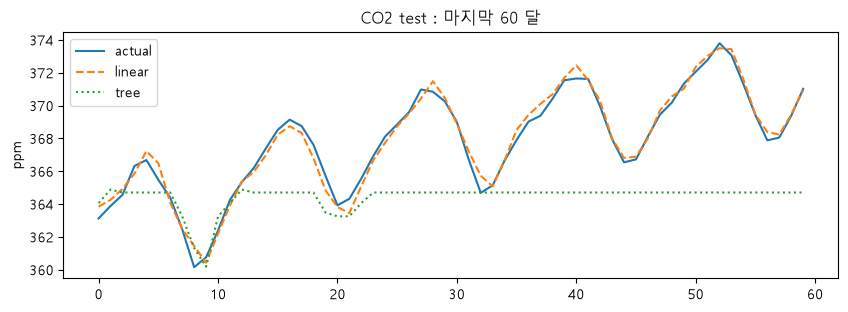

In [9]:
plt.figure(figsize=(10, 3.2))
plt.plot(yc_test.values, label="actual")
plt.plot(lin_ts.predict(Xc_test), "--", label="linear")
plt.plot(tree_ts.predict(Xc_test), ":", label="tree")
plt.title("CO2 test : 마지막 60 달"); plt.ylabel("ppm"); plt.legend(); plt.show()